# Temperature Prediction

## Objective
Predict the **temperature** based on humidity data.


## Dataset Overview
The dataset contains hourly or daily readings of humidity and temperature.


## Workflow
1. Load the dataset  
2. Explore and clean the data  
3. Train a regression model  
4. Evaluate predictions


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Load the dataset
df = pd.read_csv("humidity.csv")
df.info()
df.head()


<class 'pandas.DataFrame'>
RangeIndex: 701548 entries, 0 to 701547
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   sensor_id    701548 non-null  int64  
 1   lat          701548 non-null  float64
 2   lon          701548 non-null  float64
 3   pressure     701548 non-null  float64
 4   temperature  701548 non-null  float64
 5   humidity     701548 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 32.1 MB


,sensor_id,lat,lon,pressure,temperature,humidity
0,2266,42.738,23.272,95270.27,23.46,62.48
1,2292,42.663,23.273,94355.83,23.06,59.46
2,3096,42.700,23.360,95155.81,26.53,44.38
3,3428,42.624,23.406,94679.57,28.34,38.28
4,3472,42.669,23.318,94327.88,26.31,46.37


## Exploratory Data Analysis


In [3]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Display summary statistics
print("\nSummary Statistics:")
df.describe()


Missing values per column:
sensor_id      0
lat            0
lon            0
pressure       0
temperature    0
humidity       0
dtype: int64

Summary Statistics:


,sensor_id,lat,lon,pressure,temperature,humidity
count,701548.000000,701548.000000,701548.000000,701548.000000,701548.000000,701548.000000
mean,2835.419842,42.679722,23.333739,94965.292500,24.754990,48.348949
std,798.018890,0.025568,0.039365,2577.210945,14.013001,20.907247
min,1764.000000,42.622000,23.240000,0.000000,-145.120000,0.000000
25%,2224.000000,42.665000,23.310000,94528.017500,20.630000,34.140000
50%,2323.000000,42.685000,23.332000,95005.480000,24.780000,48.350000
75%,3474.000000,42.694000,23.360000,95405.132500,29.870000,62.940000
max,4661.000000,42.738000,23.419000,164926.750000,61.170000,100.000000


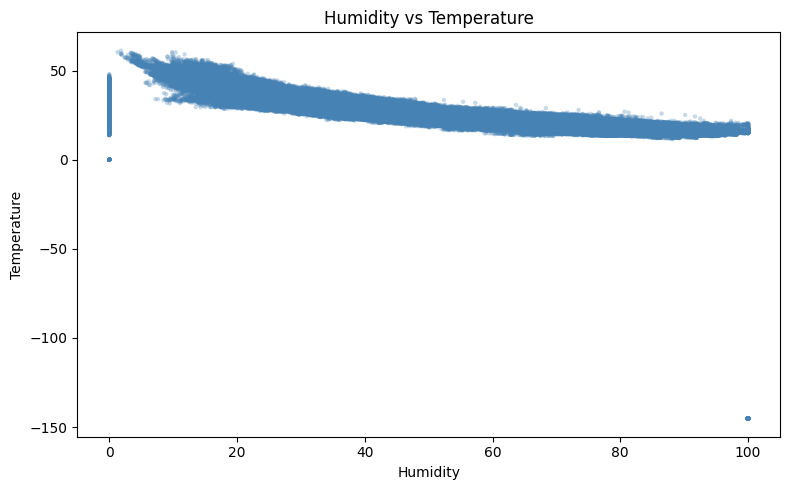

In [4]:
# Scatter plot to observe relationship
plt.figure(figsize=(8, 5))
plt.scatter(df['humidity'], df['temperature'], alpha=0.3, color='steelblue', edgecolors='none', s=10)
plt.xlabel('Humidity')
plt.ylabel('Temperature')
plt.title('Humidity vs Temperature')
plt.tight_layout()
plt.show()


## Data Preprocessing

In [5]:
# Drop any rows with missing values
df_clean = df[['humidity', 'temperature']].dropna()
print(f"Rows after cleaning: {len(df_clean)}")

# Define features and target
X = df_clean[['humidity']]
y = df_clean['temperature']

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")


Rows after cleaning: 701548
Training samples: 561238 | Test samples: 140310


## Model Training

In [6]:
# Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept : {model.intercept_:.4f}")
print(f"Coefficient (Humidity): {model.coef_[0]:.4f}")

# Predict
y_pred = model.predict(X_test)


Intercept : 41.2517
Coefficient (Humidity): -0.3412


## Evaluation


Mean Squared Error  (MSE) : 144.0848
Root Mean Sq. Error (RMSE): 12.0035
R² Score                  : 0.2570


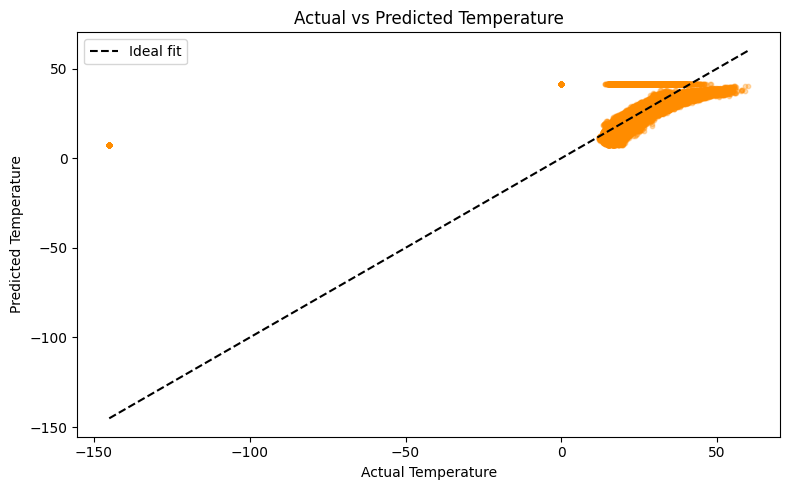

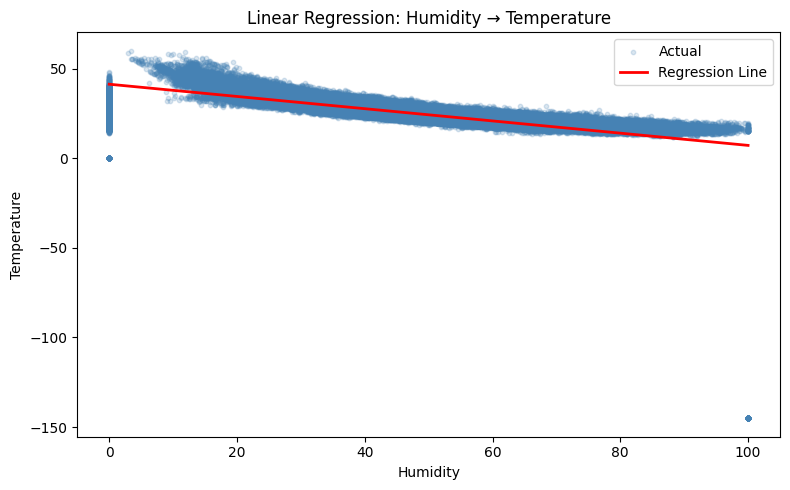

In [7]:
# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error  (MSE) : {mse:.4f}")
print(f"Root Mean Sq. Error (RMSE): {rmse:.4f}")
print(f"R² Score                  : {r2:.4f}")

# Actual vs Predicted plot
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='darkorange', s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=1.5, label='Ideal fit')
plt.xlabel('Actual Temperature')
plt.ylabel('Predicted Temperature')
plt.title('Actual vs Predicted Temperature')
plt.legend()
plt.tight_layout()
plt.show()

# Regression line over scatter
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.2, color='steelblue', s=10, label='Actual')
plt.plot(X_test.sort_values('humidity'),
         model.predict(X_test.sort_values('humidity')),
         color='red', lw=2, label='Regression Line')
plt.xlabel('Humidity')
plt.ylabel('Temperature')
plt.title('Linear Regression: Humidity → Temperature')
plt.legend()
plt.tight_layout()
plt.show()


## Conclusion
- A simple linear regression model was used to predict temperature from humidity.  
- Consider using polynomial regression or time-series models for more complex patterns.
